# Rossmann Store Sales — Phase 4.7: LightGBM / CatBoost, Tuned

Three things Phase 4.6 left on the table:

1. **`Store` was never usable as a real categorical.** Phase 3 target-encoded it into `StoreMeanLogSales` purely to dodge `HistGradientBoostingRegressor`'s 255-category cap, and Phase 4.6 then found that encoding had become redundant (dropping it *improved* the model). LightGBM and CatBoost both split on high-cardinality categoricals natively, so `Store` can finally be passed as what it is.
2. **The GBM was never tuned.** Every phase used `learning_rate=0.1` with a swept iteration count and nothing else — no leaf/depth/regularization search, and never the standard low-learning-rate-plus-many-rounds setting.
3. **The loss weighting was never explored.** RMSPE is exactly weighted MSE with `w = 1/y²`, so it needs no custom objective — `sample_weight` expresses it directly.

**Discipline:** every choice below — weighting, hyperparameters, `Store` representation, ensemble weights, calibration factor — is made against the **inner** split (models trained on `inner_train`, scored on `inner_val`). `val_fold` is touched once at the end. `test.csv` stays unseen until Phase 5.

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
pio.templates.default = "plotly_white"
warnings.filterwarnings("ignore")

import lightgbm as lgb
from catboost import CatBoostRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

from rossmann_features import (
    prepare_store_table, add_features, NUMERIC_COLS,
    fit_store_dow_promo_mean, predict_store_dow_promo_mean,
    fit_store_target_encoding, add_store_target_encoding,
)
import rossmann_features_v2 as f2
from rossmann_nn import rmspe

train = pd.read_csv("train.csv", parse_dates=["Date"], low_memory=False, dtype={"StateHoliday": str})
store_prepared = prepare_store_table(pd.read_csv("store.csv"))
with open("phase1_split_config.json") as f:
    val_start = pd.Timestamp(json.load(f)["val_start"])

train_fold = add_features(train[train["Date"] < val_start].copy(), store_prepared)
val_fold = add_features(train[train["Date"] >= val_start].copy(), store_prepared)
train_fold_open = train_fold[train_fold["Open"] == 1]
train_fit = train_fold[(train_fold["Open"] == 1) & (train_fold["Sales"] > 0)].copy()
OUTER_CUTOFF = train_fold["Date"].max()

inner_val_start = OUTER_CUTOFF - pd.Timedelta(days=41)
INNER_CUTOFF = inner_val_start - pd.Timedelta(days=1)
inner_train_raw = train_fit[train_fit["Date"] < inner_val_start].copy()
inner_val_raw = train_fold[(train_fold["Date"] >= inner_val_start) & (train_fold["Open"] == 1)].copy()
inner_history_open = train_fold_open[train_fold_open["Date"] <= INNER_CUTOFF]

# Schedule features use only Promo/StateHoliday/SchoolHoliday/Open/Date -- never Sales --
# so one panel-wide pass is fold-independent and safe to share.
panel = f2.add_schedule_features(pd.concat([train_fold, val_fold], ignore_index=True))
sched_lookup = panel[["Store", "Date"] + f2.SCHEDULE_COLS]
print("inner:", inner_train_raw.Date.min().date(), "->", INNER_CUTOFF.date(),
      "| eval", inner_val_raw.Date.min().date(), "->", inner_val_raw.Date.max().date())
print("outer:", train_fit.Date.min().date(), "->", OUTER_CUTOFF.date(),
      "| eval", val_fold.Date.min().date(), "->", val_fold.Date.max().date())

inner: 2013-01-01 -> 2015-05-08 | eval 2015-05-09 -> 2015-06-19
outer: 2013-01-01 -> 2015-06-19 | eval 2015-06-20 -> 2015-07-31


In [2]:
# Everything Sales-derived is fit per fold on that fold's history only.
def make_fold(history_open, cutoff, train_rows, eval_rows):
    sd = fit_store_dow_promo_mean(history_open)
    gm = history_open["Sales"].mean()
    enc = fit_store_target_encoding(history_open)
    gml = np.log1p(history_open["Sales"]).mean()
    roll = f2.build_daily_rolling_table(history_open)
    trends = f2.fit_store_trend(history_open)

    def build(df, mode):
        df = f2.assign_training_origins(df, cutoff) if mode == "training" else \
             f2.assign_fixed_origin(df, cutoff)
        df = f2.attach_rolling(df, roll, fallback_source=history_open)
        fb = predict_store_dow_promo_mean(df, sd, gm)
        df = f2.add_yearago_features(df, history_open, fb)
        df = add_store_target_encoding(df, enc, gml)   # kept only for the representation ablation
        n = len(df)
        df = df.merge(sched_lookup, on=["Store", "Date"], how="left")
        assert len(df) == n, "schedule merge changed row count"
        return f2.add_promo2_duration(f2.add_store_trend(df, trends))

    return build(train_rows.copy(), "training"), build(eval_rows.copy(), "frozen")

t0 = time.time()
IN_TR, IN_EV = make_fold(inner_history_open, INNER_CUTOFF, inner_train_raw, inner_val_raw)
OUT_TR, OUT_EV = make_fold(train_fold_open, OUTER_CUTOFF, train_fit, val_fold)
print(f"folds built in {time.time()-t0:.0f}s -> inner {IN_TR.shape}/{IN_EV.shape}, outer {OUT_TR.shape}/{OUT_EV.shape}")

CAT = ["Store", "DayOfWeek", "Month", "StoreType", "Assortment", "StateHoliday"]
NUM = NUMERIC_COLS + f2.LAG_COLS_V2 + f2.SCHEDULE_COLS + f2.EXTRA_NUMERIC_COLS
FEATS = CAT + NUM

letters = sorted(set(train_fold["StoreType"]) | set(train_fold["Assortment"]) | set(train_fold["StateHoliday"].astype(str)))
code = {v: i for i, v in enumerate(letters)}
for d in (IN_TR, IN_EV, OUT_TR, OUT_EV):
    for c in ["StoreType", "Assortment", "StateHoliday"]:
        d[c] = d[c].astype(str).map(code)
    for c in CAT:
        d[c] = d[c].astype("int32")

def parts(tr, ev):
    return (tr[FEATS], np.log1p(tr["Sales"].to_numpy()), tr["Sales"].to_numpy(),
            ev[FEATS], ev["Sales"].to_numpy(), ev["Open"].to_numpy())

Xi, yi, si, Xie, sie, oie = parts(IN_TR, IN_EV)
Xo, yo, so, Xoe, soe, ooe = parts(OUT_TR, OUT_EV)

def finish(pred_log, open_flag):
    return np.where(open_flag == 0, 0, np.clip(np.expm1(pred_log), 0, None))

print("features:", len(FEATS), "| Store levels:", IN_TR.Store.nunique())

folds built in 4s -> inner (766584, 45)/(37473, 45), outer (804056, 45)/(46830, 45)


features: 34 | Store levels: 1115


In [3]:
# --- Loss weighting, selected on the INNER split ---
# RMSPE == weighted MSE with w = 1/y^2, so no custom objective is required. But applying
# that weight literally fights the log1p target, which already encodes relative error
# ((y-yhat)/y ~= log y - log yhat for small errors). Sweeping the exponent p in
# w = 1/log1p(y)^p interpolates between "no extra weight" (p=0) and RMSPE's emphasis on
# low-sales rows, without 1/y^2's extreme variance.
def lgb_fit(X, y, w=None, cat=CAT, **kw):
    params = dict(n_estimators=300, learning_rate=0.1, num_leaves=63, verbose=-1, random_state=0)
    params.update(kw)
    m = lgb.LGBMRegressor(**params)
    m.fit(X, y, sample_weight=w, categorical_feature=cat)
    return m

weight_rows = []
for p in [0, 1, 2, 3]:
    w = None if p == 0 else 1.0 / np.log1p(si) ** p
    t0 = time.time()
    m = lgb_fit(Xi, yi, w)
    r = rmspe(sie, finish(m.predict(Xie), oie))
    weight_rows.append({"p": p, "inner_rmspe": r})
    print(f"w = 1/log1p(y)^{p}   inner RMSPE = {r:.4f}   ({time.time()-t0:.0f}s)")

# Direct RMSPE weighting on the raw target, for the record.
m = lgb_fit(Xi, si.astype(float), 1.0 / si.astype(float) ** 2)
r_direct = rmspe(sie, np.where(oie == 0, 0, np.clip(m.predict(Xie), 0, None)))
print(f"raw target, w = 1/y^2 (literal RMSPE)   inner RMSPE = {r_direct:.4f}")

BEST_P = int(min(weight_rows, key=lambda d: d["inner_rmspe"])["p"])
WEIGHT = (lambda s: None) if BEST_P == 0 else (lambda s: 1.0 / np.log1p(s) ** BEST_P)
print(f"\nselected p = {BEST_P} (on inner split)")

w = 1/log1p(y)^0   inner RMSPE = 0.1111   (6s)


w = 1/log1p(y)^1   inner RMSPE = 0.1094   (6s)


w = 1/log1p(y)^2   inner RMSPE = 0.1148   (6s)


w = 1/log1p(y)^3   inner RMSPE = 0.1194   (5s)


raw target, w = 1/y^2 (literal RMSPE)   inner RMSPE = 0.1579

selected p = 1 (on inner split)


In [4]:
# --- LightGBM tuning on the inner split ---
# Low learning rate with many rounds, iteration count chosen by early stopping against
# inner_val -- the selection fold, never val_fold.
CONFIGS = [
    {"learning_rate": 0.10, "num_leaves": 63,  "min_child_samples": 20},
    {"learning_rate": 0.03, "num_leaves": 63,  "min_child_samples": 20},
    {"learning_rate": 0.03, "num_leaves": 127, "min_child_samples": 20},
    {"learning_rate": 0.03, "num_leaves": 255, "min_child_samples": 50},
    {"learning_rate": 0.03, "num_leaves": 127, "min_child_samples": 50,
     "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1},
    {"learning_rate": 0.02, "num_leaves": 255, "min_child_samples": 50,
     "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 10.0},
]

w_in = WEIGHT(si)
tuning = []
for cfg in CONFIGS:
    t0 = time.time()
    m = lgb.LGBMRegressor(n_estimators=5000, verbose=-1, random_state=0, **cfg)
    m.fit(Xi, yi, sample_weight=w_in, categorical_feature=CAT,
          eval_set=[(Xie, np.log1p(sie))], eval_metric="l2",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    r = rmspe(sie, finish(m.predict(Xie), oie))
    tuning.append({**cfg, "best_iter": m.best_iteration_, "inner_rmspe": r, "secs": time.time() - t0})
    print(f"lr={cfg['learning_rate']:<5} leaves={cfg['num_leaves']:<4} "
          f"mcs={cfg['min_child_samples']:<3} -> iters={m.best_iteration_:<5} "
          f"inner RMSPE={r:.4f}  ({time.time()-t0:.0f}s)")

tune_df = pd.DataFrame(tuning).sort_values("inner_rmspe")
BEST_LGB = {k: v for k, v in tune_df.iloc[0].items()
            if k not in ("best_iter", "inner_rmspe", "secs") and pd.notna(v)}
BEST_LGB_ITERS = int(tune_df.iloc[0]["best_iter"])
for k in ("num_leaves", "min_child_samples", "bagging_freq"):
    if k in BEST_LGB:
        BEST_LGB[k] = int(BEST_LGB[k])
print("\nbest LightGBM config (inner):", BEST_LGB, "| iters:", BEST_LGB_ITERS)

lr=0.1   leaves=63   mcs=20  -> iters=374   inner RMSPE=0.1085  (8s)


lr=0.03  leaves=63   mcs=20  -> iters=1392  inner RMSPE=0.1090  (27s)


lr=0.03  leaves=127  mcs=20  -> iters=1024  inner RMSPE=0.1076  (30s)


lr=0.03  leaves=255  mcs=50  -> iters=757   inner RMSPE=0.1113  (32s)


lr=0.03  leaves=127  mcs=50  -> iters=1887  inner RMSPE=0.1047  (51s)


lr=0.02  leaves=255  mcs=50  -> iters=1855  inner RMSPE=0.1043  (75s)

best LightGBM config (inner): {'learning_rate': 0.02, 'num_leaves': 255, 'min_child_samples': 50, 'feature_fraction': 0.8, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'lambda_l2': 10.0} | iters: 1855


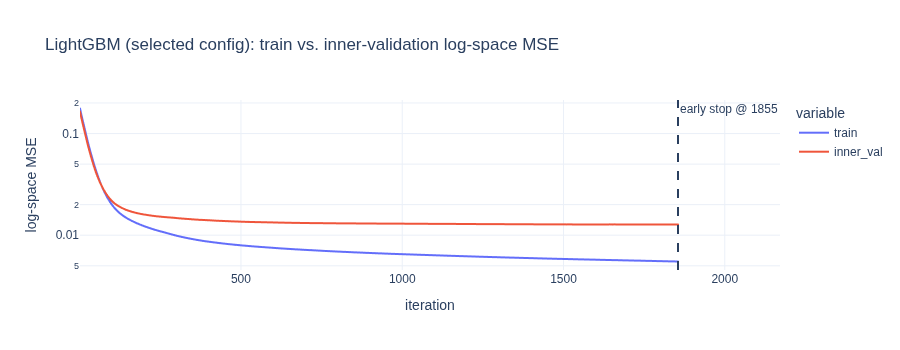

final train MSE=0.00551 | inner_val MSE=0.01275


In [5]:
# Train-vs-validation curve for the selected config, on the natural boosting axis.
# The training eval set is subsampled: LightGBM scores every eval_set at every iteration,
# so scoring all ~766k training rows for hundreds of iterations would cost far more than
# the fit itself, and a 100k-row sample traces the same curve.
rng = np.random.default_rng(0)
sub = rng.choice(len(Xi), size=min(100_000, len(Xi)), replace=False)

m_curve = lgb.LGBMRegressor(n_estimators=max(BEST_LGB_ITERS, 200), verbose=-1, random_state=0, **BEST_LGB)
m_curve.fit(Xi, yi, sample_weight=w_in, categorical_feature=CAT,
            eval_set=[(Xi.iloc[sub], yi[sub]), (Xie, np.log1p(sie))],
            eval_names=["train (100k sample)", "inner_val"], eval_metric="l2")
curve = pd.DataFrame({
    "iteration": range(1, len(m_curve.evals_result_["inner_val"]["l2"]) + 1),
    "train": m_curve.evals_result_["train (100k sample)"]["l2"],
    "inner_val": m_curve.evals_result_["inner_val"]["l2"],
})
fig = px.line(curve, x="iteration", y=["train", "inner_val"],
              title="LightGBM (selected config): train vs. inner-validation log-space MSE")
fig.update_layout(height=350, yaxis_title="log-space MSE", yaxis_type="log")
fig.add_vline(x=BEST_LGB_ITERS, line_dash="dash", annotation_text=f"early stop @ {BEST_LGB_ITERS}")
fig.show()
print(f"final train MSE={curve['train'].iloc[-1]:.5f} | inner_val MSE={curve['inner_val'].iloc[-1]:.5f}")


In [6]:
# --- How should `Store` be represented? Selected on inner. ---
# Phase 3 had to target-encode it (HGB caps categoricals at 255 levels); Phase 4.6 found
# that encoding had become redundant. LightGBM removes the constraint entirely, so all
# three options are finally comparable on equal terms.
store_variants = {
    "native categorical (1,115 levels)": (CAT, NUM),
    "target-encoded StoreMeanLogSales": ([c for c in CAT if c != "Store"], NUM + ["StoreMeanLogSales"]),
    "no store identity at all": ([c for c in CAT if c != "Store"], NUM),
    "native categorical + target encoding": (CAT, NUM + ["StoreMeanLogSales"]),
}
store_rows = []
for label, (cats, nums) in store_variants.items():
    cols = cats + nums
    m = lgb.LGBMRegressor(n_estimators=BEST_LGB_ITERS, verbose=-1, random_state=0, **BEST_LGB)
    m.fit(IN_TR[cols], yi, sample_weight=w_in, categorical_feature=cats)
    r = rmspe(sie, finish(m.predict(IN_EV[cols]), oie))
    store_rows.append({"representation": label, "inner_rmspe": r})
    print(f"{label:38} inner RMSPE = {r:.4f}")
store_df = pd.DataFrame(store_rows).sort_values("inner_rmspe")

native categorical (1,115 levels)      inner RMSPE = 0.1038


target-encoded StoreMeanLogSales       inner RMSPE = 0.1125


no store identity at all               inner RMSPE = 0.1134


native categorical + target encoding   inner RMSPE = 0.1035


In [7]:
# --- CatBoost, for ensemble diversity ---
# Its ordered target statistics treat `Store` completely differently from LightGBM's
# split-based approach, which is the point: decorrelated errors are what makes an ensemble
# worth having. Kept to two configs because it is by far the slowest model here (a probe
# put it at ~5x LightGBM's fit time for worse standalone accuracy), and GPU only buys
# ~1.5x. The winning config's inner predictions are retained so the ensemble step below
# does not have to pay for the fit twice.
CB_CONFIGS = [
    {"iterations": 1000, "learning_rate": 0.05, "depth": 8},
    {"iterations": 1500, "learning_rate": 0.03, "depth": 10},
]
cb_rows, cb_preds = [], {}
for i, cfg in enumerate(CB_CONFIGS):
    t0 = time.time()
    m = CatBoostRegressor(task_type="GPU", verbose=0, random_seed=0, allow_writing_files=False, **cfg)
    m.fit(Xi, yi, cat_features=CAT, sample_weight=w_in)
    p = finish(m.predict(Xie), oie)
    r = rmspe(sie, p)
    cb_rows.append({**cfg, "inner_rmspe": r})
    cb_preds[i] = p
    print(f"CatBoost lr={cfg['learning_rate']} depth={cfg['depth']} iters={cfg['iterations']} "
          f"-> inner RMSPE={r:.4f}  ({time.time()-t0:.0f}s)")

cb_df = pd.DataFrame(cb_rows)
best_i = int(cb_df["inner_rmspe"].idxmin())
BEST_CB = {k: int(v) if k in ("iterations", "depth") else float(v)
           for k, v in CB_CONFIGS[best_i].items()}
CB_INNER_PRED = cb_preds[best_i]
print("\nbest CatBoost config (inner):", BEST_CB)


CatBoost lr=0.05 depth=8 iters=1000 -> inner RMSPE=0.1099  (165s)


CatBoost lr=0.03 depth=10 iters=1500 -> inner RMSPE=0.1093  (330s)

best CatBoost config (inner): {'iterations': 1500, 'learning_rate': 0.03, 'depth': 10}


In [8]:
# --- Predictions from each family on both folds, for fitting the ensemble + calibration ---
# HGB is kept as a third member purely for diversity; it cannot take `Store` at all (255-
# category cap), so it runs on the Phase 4.6 feature set. Its categorical indices must be
# computed against the REDUCED column list -- indexing into FEATS would be off by one for
# every column after the dropped `Store`.
HGB_FEATS = [c for c in FEATS if c != "Store"]
HGB_CAT_IDX = [HGB_FEATS.index(c) for c in CAT if c != "Store"]

def fit_predict(kind, Xtr, ytr, wtr, Xev):
    if kind == "lgb":
        m = lgb.LGBMRegressor(n_estimators=BEST_LGB_ITERS, verbose=-1, random_state=0, **BEST_LGB)
        m.fit(Xtr, ytr, sample_weight=wtr, categorical_feature=CAT)
        return m.predict(Xev)
    if kind == "cat":
        m = CatBoostRegressor(task_type="GPU", verbose=0, random_seed=0,
                              allow_writing_files=False, **BEST_CB)
        m.fit(Xtr, ytr, cat_features=CAT, sample_weight=wtr)
        return m.predict(Xev)
    m = HistGradientBoostingRegressor(categorical_features=HGB_CAT_IDX, learning_rate=0.1,
                                       max_iter=700, early_stopping=False, random_state=0)
    m.fit(Xtr[HGB_FEATS], ytr, sample_weight=wtr)
    return m.predict(Xev[HGB_FEATS])

MEMBERS = ["lgb", "cat", "hgb"]
w_out = WEIGHT(so)
inner_pred = {"cat": CB_INNER_PRED}   # reused from tuning rather than refitting
outer_pred = {}
for k in MEMBERS:
    t0 = time.time()
    if k not in inner_pred:
        inner_pred[k] = finish(fit_predict(k, Xi, yi, w_in, Xie), oie)
    outer_pred[k] = finish(fit_predict(k, Xo, yo, w_out, Xoe), ooe)
    print(f"{k:4} inner={rmspe(sie, inner_pred[k]):.4f}  outer={rmspe(soe, outer_pred[k]):.4f} "
          f"({time.time()-t0:.0f}s)")


lgb  inner=0.1043  outer=0.1111 (154s)


cat  inner=0.1093  outer=0.1194 (342s)


hgb  inner=0.1212  outer=0.1235 (40s)


In [9]:
# --- Ensemble weights + shrink factor, fitted on inner, then frozen (same as Phase 4.5) ---
EPS = 1.0
GRID = np.arange(0.90, 1.0801, 0.001)

def best_factor(pred, sales):
    sc = [rmspe(sales, pred * f) for f in GRID]
    i = int(np.argmin(sc))
    return float(GRID[i]), float(sc[i])

log_in = np.column_stack([np.log(inner_pred[k] + EPS) for k in MEMBERS])
log_out = np.column_stack([np.log(outer_pred[k] + EPS) for k in MEMBERS])

STEP = 0.05
units = int(round(1 / STEP))
grid_w = np.array([(a, b, units - a - b) for a in range(units + 1)
                   for b in range(units + 1 - a)], dtype=float) * STEP

def blend(w, f, logp, open_flag):
    p = np.clip(np.exp(logp @ w) - EPS, 0, None) * f
    return np.where(open_flag == 0, 0, p)

W, F = np.array([1.0] + [0.0] * (len(MEMBERS) - 1)), 1.0
for _ in range(3):
    sc = [rmspe(sie, blend(w, F, log_in, oie)) for w in grid_w]
    W = grid_w[int(np.argmin(sc))]
    F, inner_ens = best_factor(np.clip(np.exp(log_in @ W) - EPS, 0, None), sie)
print("fitted on inner (frozen):", {k: round(v, 2) for k, v in zip(MEMBERS, W)},
      f"| factor={F:.3f} | inner RMSPE={inner_ens:.4f}")

per_model_factor = {k: best_factor(inner_pred[k], sie)[0] for k in MEMBERS}
print("per-model inner-fitted factors:", {k: round(v, 3) for k, v in per_model_factor.items()})

fitted on inner (frozen): {'lgb': np.float64(0.75), 'cat': np.float64(0.25), 'hgb': np.float64(0.0)} | factor=0.995 | inner RMSPE=0.1034
per-model inner-fitted factors: {'lgb': 0.995, 'cat': 0.993, 'hgb': 0.975}


   model  val_raw  val_calibrated
     lgb   0.1111          0.1104
     cat   0.1194          0.1182
     hgb   0.1235          0.1273
ENSEMBLE      NaN          0.1107

                              model  rmspe
      Phase 1: baseline + shrinkage 0.1448
         Phase 3: HGB (v1 features) 0.1412
      Phase 4: entity-embedding MLP 0.1412
Phase 4.5: calibrated ensemble (v1) 0.1257
       Phase 4.6: HGB (v2 features) 0.1281
          Phase 4.7: LightGBM tuned 0.1111
     Phase 4.7: calibrated ensemble 0.1107


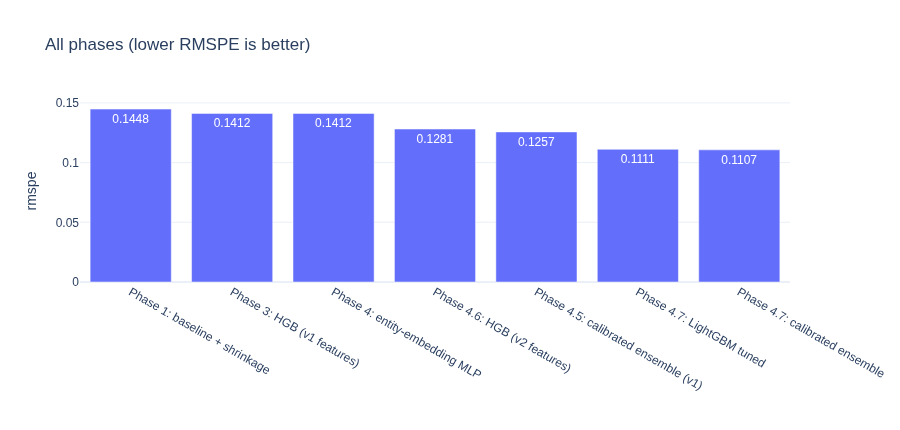

In [10]:
# --- Single evaluation on val_fold, applying only frozen constants ---
pred_ens = blend(W, F, log_out, ooe)
rows = []
for k in MEMBERS:
    rows.append({"model": k, "val_raw": rmspe(soe, outer_pred[k]),
                 "val_calibrated": rmspe(soe, np.where(ooe == 0, 0, outer_pred[k] * per_model_factor[k]))})
rows.append({"model": "ENSEMBLE", "val_raw": np.nan, "val_calibrated": rmspe(soe, pred_ens)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

history = pd.DataFrame([
    {"model": "Phase 1: baseline + shrinkage", "rmspe": 0.1448},
    {"model": "Phase 3: HGB (v1 features)", "rmspe": 0.1412},
    {"model": "Phase 4: entity-embedding MLP", "rmspe": 0.1412},
    {"model": "Phase 4.5: calibrated ensemble (v1)", "rmspe": 0.1257},
    {"model": "Phase 4.6: HGB (v2 features)", "rmspe": 0.1281},
    {"model": "Phase 4.7: LightGBM tuned", "rmspe": rmspe(soe, outer_pred["lgb"])},
    {"model": "Phase 4.7: calibrated ensemble", "rmspe": rmspe(soe, pred_ens)},
])
print()
print(history.round(4).to_string(index=False))

fig = px.bar(history.sort_values("rmspe", ascending=False), x="model", y="rmspe", text_auto=".4f",
             title="All phases (lower RMSPE is better)")
fig.update_layout(height=430, xaxis_title="")
fig.show()

In [11]:
diag = OUT_EV[["Store", "Date", "Sales", "Open", "DayOfWeek"]].copy()
diag["pred_lgb"] = outer_pred["lgb"]
diag["pred_ensemble"] = pred_ens
diag["horizon_week"] = ((diag["Date"] - OUTER_CUTOFF).dt.days - 1) // 7 + 1

def by(col):
    return pd.DataFrame({k: {c: rmspe(g["Sales"], g[c]) for c in ["pred_lgb", "pred_ensemble"]}
                         for k, g in diag.groupby(col)}).T

print("RMSPE by DayOfWeek (1=Mon ... 7=Sun):")
print(by("DayOfWeek").round(4).to_string())
print("\nRMSPE by horizon week:")
print(by("horizon_week").round(4).to_string())
print("\nhorizon spread (max-min):", by("horizon_week").agg(lambda s: s.max() - s.min()).round(4).to_dict())

print("\nTop 20 LightGBM feature importances (gain):")
m_final = lgb.LGBMRegressor(n_estimators=BEST_LGB_ITERS, verbose=-1, random_state=0,
                            importance_type="gain", **BEST_LGB)
m_final.fit(Xo, yo, sample_weight=WEIGHT(so), categorical_feature=CAT)
imp = pd.Series(m_final.feature_importances_, index=FEATS).sort_values(ascending=False)
print((imp / imp.sum()).head(20).round(4).to_string())

history.to_csv("phase47_results.csv", index=False)
diag.to_csv("phase47_val_predictions.csv", index=False)
tune_df.to_csv("phase47_lgb_tuning.csv", index=False)
with open("phase47_params.json", "w") as f:
    json.dump({"weight_exponent_p": BEST_P, "lgb": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v)
                                                     for k, v in BEST_LGB.items()},
               "lgb_iters": BEST_LGB_ITERS, "catboost": {k: float(v) for k, v in BEST_CB.items()},
               "members": MEMBERS, "ensemble_weights": W.tolist(), "ensemble_factor": F,
               "per_model_factors": per_model_factor,
               "store_representation": store_df.iloc[0]["representation"]}, f, indent=2)
print("\nSaved phase47_results.csv, phase47_val_predictions.csv, phase47_lgb_tuning.csv, phase47_params.json")

RMSPE by DayOfWeek (1=Mon ... 7=Sun):
   pred_lgb  pred_ensemble
1    0.0998         0.0999
2    0.1027         0.1021
3    0.1036         0.1032
4    0.1024         0.1032
5    0.1173         0.1162
6    0.1351         0.1342
7    0.1536         0.1472

RMSPE by horizon week:
   pred_lgb  pred_ensemble
1    0.1018         0.1007
2    0.1183         0.1181
3    0.1294         0.1291
4    0.1009         0.0991
5    0.0992         0.0996
6    0.1139         0.1139

horizon spread (max-min): {'pred_lgb': 0.0302, 'pred_ensemble': 0.03}

Top 20 LightGBM feature importances (gain):


SalesYearAgo              0.5107
SalesRollMean90           0.1872
Store                     0.0500
Promo                     0.0428
SalesRollMean30           0.0393
DaysSincePromo            0.0321
DaysUntilPromo            0.0206
Trend                     0.0144
DaysUntilStateHoliday     0.0130
WeekOfYear                0.0112
DayOfWeek                 0.0109
DayOfMonth                0.0104
DaysSinceStateHoliday     0.0097
Month                     0.0085
WasClosedYesterday        0.0083
SalesRollMean7            0.0064
WillBeClosedTomorrow      0.0050
StoreTrend                0.0033
HorizonDay                0.0031
DaysSinceSchoolHoliday    0.0027

Saved phase47_results.csv, phase47_val_predictions.csv, phase47_lgb_tuning.csv, phase47_params.json
